# E23CSEU0388_Assignment-9 


In [1]:
%pip install -q opencv-python scikit-learn matplotlib seaborn tqdm pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, random, math, warnings
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cpu")  # CPU-only; no GPU required
print("Device:", DEVICE)

c:\Users\SHIVANK\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


In [3]:
from pathlib import Path
import os

# Notebook and dataset are both inside CSET343/Assignment-9.
# Expected dataset folder:
# Assignment-9/UR_fall_detection_dataset_cam0_rgb/
NOTEBOOK_DIR = Path.cwd()
DATASET_DIR = NOTEBOOK_DIR / "UR_fall_detection_dataset_cam0_rgb"

# CPU-friendly settings (GPU not required)
NUM_FRAMES = 8
IMAGE_SIZE = 64
BATCH_SIZE = 1
EPOCHS = 5
LEARNING_RATE = 1e-4
NUM_WORKERS = 0

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Current working directory:", Path.cwd())
print("Dataset path:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

def infer_label_from_name(name):
    """URFD convention: ADL/normal = 0, fall = 1."""
    n = name.lower().replace("_", "-")
    if "adl" in n or "normal" in n or "non-fall" in n or "nonfall" in n:
        return 0
    if "fall" in n:
        return 1
    return None

def list_frame_files(folder):
    return sorted(
        [p for p in folder.iterdir()
         if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS],
        key=lambda p: p.name.lower()
    )

def discover_sequences(root: Path):
    if not root.exists():
        raise FileNotFoundError(
            f"Dataset folder not found: {root}. "
            "Ensure VS Code's notebook working directory is Assignment-9."
        )
    rows = []
    for folder in root.rglob("*"):
        if not folder.is_dir():
            continue
        label = infer_label_from_name(folder.name)
        if label is None:
            continue
        frames = list_frame_files(folder)
        if frames:
            rows.append({
                "path": str(folder),
                "label": label,
                "filename": folder.name,
                "num_frames_found": len(frames)
            })
    df = pd.DataFrame(rows).drop_duplicates(subset=["path"])
    if df.empty:
        raise RuntimeError(
            "No ADL/fall sequence folders containing image frames found. "
            "Expected folders such as adl-01-cam0-rgb with PNG images."
        )
    return df

video_df = discover_sequences(DATASET_DIR)
print("Sequence folders found:", len(video_df))
display(video_df.head(10))
print("\\nLabel counts (0=ADL/normal, 1=fall):")
display(video_df["label"].value_counts().sort_index().rename(
    index={0: "Normal / ADL", 1: "Fall"}).to_frame("count"))

Current working directory: e:\BU\7th Sem\CSET343\Assignment-9
Dataset path: e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_detection_dataset_cam0_rgb
Dataset exists: True
Sequence folders found: 70


,path,label,filename,num_frames_found
0,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-01-cam0-rgb,150
1,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-02-cam0-rgb,180
2,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-03-cam0-rgb,180
3,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-04-cam0-rgb,150
4,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-05-cam0-rgb,180
5,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-06-cam0-rgb,230
6,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-07-cam0-rgb,180
7,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-08-cam0-rgb,180
8,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-09-cam0-rgb,150
9,e:\BU\7th Sem\CSET343\Assignment-9\UR_fall_det...,0,adl-10-cam0-rgb,300


\nLabel counts (0=ADL/normal, 1=fall):


,count
label,
Normal / ADL,40
Fall,30


## Verify videos and explore samples
This scans each video with OpenCV, reports files that cannot be opened, and displays representative frames. Corrupt/unreadable files are removed from the usable manifest.

Checking frame folders: 100%|██████████| 70/70 [00:02<00:00, 27.10it/s]

Valid sequences: 70 | Corrupt/unreadable: 0
Usable label counts:


,count
label,
Normal / ADL,40
Fall,30


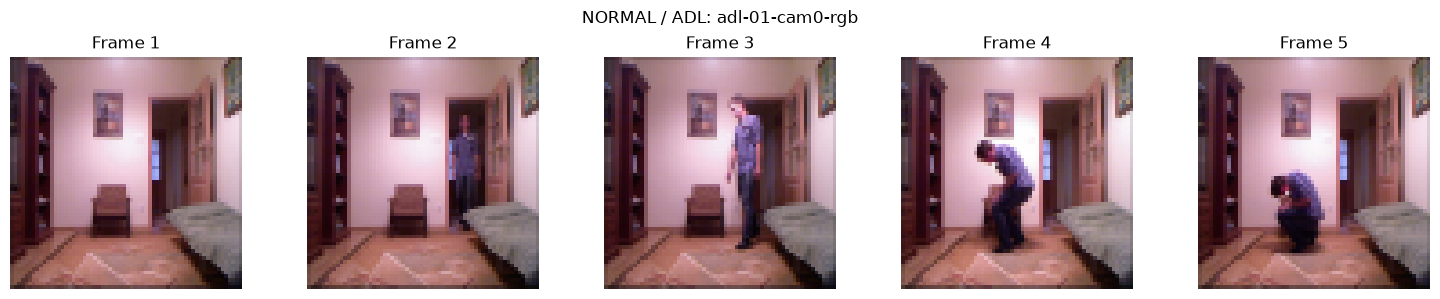

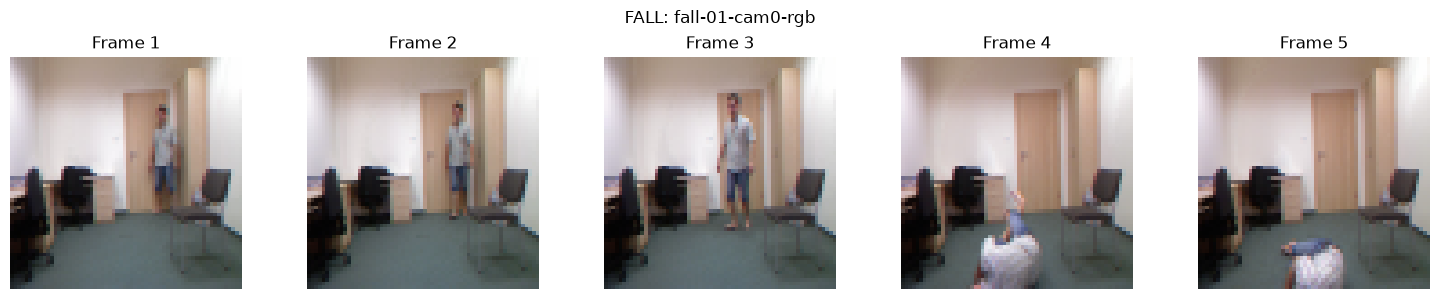

In [4]:
def read_sequence_frames(folder_path, num_frames=NUM_FRAMES,
                         image_size=IMAGE_SIZE, random_start=False):
    """Load a fixed-length clip from a folder of ordered RGB frame images."""
    folder = Path(folder_path)
    files = list_frame_files(folder)
    if not files:
        return None

    if random_start and len(files) > num_frames:
        start = random.randint(0, len(files) - num_frames)
        indices = np.linspace(start, min(len(files)-1, start+num_frames-1),
                              num_frames).astype(int)
    else:
        indices = np.linspace(0, len(files)-1, num_frames).astype(int)

    frames = []
    for idx in indices:
        frame = cv2.imread(str(files[int(idx)]), cv2.IMREAD_COLOR)
        if frame is None:
            return None
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame = cv2.resize(frame, (image_size, image_size),
                           interpolation=cv2.INTER_AREA)
        frames.append(frame)
    return np.stack(frames).astype(np.uint8)

# Verify sequences and remove folders with missing/unreadable images.
valid_rows, bad_rows = [], []
for row in tqdm(video_df.itertuples(index=False), total=len(video_df),
                desc="Checking frame folders"):
    sample = read_sequence_frames(row.path, num_frames=4, image_size=64)
    item = {"path": row.path, "label": int(row.label),
            "filename": row.filename,
            "num_frames_found": int(row.num_frames_found)}
    (valid_rows if sample is not None else bad_rows).append(item)

video_df = pd.DataFrame(valid_rows)
print("Valid sequences:", len(video_df), "| Corrupt/unreadable:", len(bad_rows))
if bad_rows:
    display(pd.DataFrame(bad_rows))
print("Usable label counts:")
display(video_df["label"].value_counts().sort_index().rename(
    index={0: "Normal / ADL", 1: "Fall"}).to_frame("count"))

def show_sequence_sample(row, frames_to_show=5):
    arr = read_sequence_frames(row["path"], num_frames=frames_to_show,
                               image_size=IMAGE_SIZE)
    if arr is None:
        print("Could not read", row["path"])
        return
    fig, axes = plt.subplots(1, len(arr), figsize=(3*len(arr), 3))
    if len(arr) == 1:
        axes = [axes]
    for i, (ax, frame) in enumerate(zip(axes, arr)):
        ax.imshow(frame)
        ax.set_title(f"Frame {i+1}")
        ax.axis("off")
    label = "FALL" if int(row["label"]) == 1 else "NORMAL / ADL"
    fig.suptitle(f"{label}: {row['filename']}")
    plt.tight_layout()
    plt.show()

if len(video_df):
    for label in [0, 1]:
        subset = video_df[video_df.label == label]
        if len(subset):
            show_sequence_sample(subset.iloc[0])

## Train/validation/test split (70% / 15% / 15%)
The split is performed at video level, not frame level, to reduce leakage between sets. Stratification is used when each class has enough examples.

In [5]:
if len(video_df) < 6 or video_df["label"].nunique() < 2:
    raise ValueError("Need at least 6 labelled videos and examples from both classes. Check dataset labels.")

def safe_stratify(labels):
    return labels if labels.value_counts().min() >= 2 else None

train_df, temp_df = train_test_split(
    video_df, test_size=0.30, random_state=SEED,
    stratify=safe_stratify(video_df["label"])
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED,
    stratify=safe_stratify(temp_df["label"])
)
for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name}: {len(part)} videos ({len(part)/len(video_df):.1%})")
    print(part["label"].value_counts().sort_index().rename(index={0:"Normal",1:"Fall"}).to_dict())

Train: 49 videos (70.0%)
{'Normal': 28, 'Fall': 21}
Validation: 10 videos (14.3%)
{'Normal': 6, 'Fall': 4}
Test: 11 videos (15.7%)
{'Normal': 6, 'Fall': 5}


## Dataset and augmentation
Each activity folder contains sequential PNG frames (as shown in your screenshot). Each clip is sampled to a fixed number of frames, resized to 64×64, converted to RGB, and normalized to [0, 1]. Augmentation is applied to training clips only: horizontal flip, small rotation, and temporal jitter via random start frames.

In [6]:
class FallVideoDataset(Dataset):
    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True).copy()
        self.training = training

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        frames = read_sequence_frames(
            row["path"], num_frames=NUM_FRAMES, image_size=IMAGE_SIZE,
            random_start=self.training
        )
        if frames is None:
            # Should rarely occur after validation; defensive fallback.
            frames = np.zeros((NUM_FRAMES, IMAGE_SIZE, IMAGE_SIZE, 3),
                              dtype=np.uint8)

        # Apply consistent spatial augmentation to every frame in the clip.
        if self.training:
            if random.random() < 0.5:
                frames = frames[:, :, ::-1, :].copy()
            if random.random() < 0.3:
                angle = random.uniform(-8, 8)
                matrix = cv2.getRotationMatrix2D(
                    (IMAGE_SIZE/2, IMAGE_SIZE/2), angle, 1.0)
                frames = np.stack([
                    cv2.warpAffine(f, matrix, (IMAGE_SIZE, IMAGE_SIZE),
                                   borderMode=cv2.BORDER_REFLECT_101)
                    for f in frames
                ])

        frames = frames.astype(np.float32) / 255.0
        # [T,H,W,C] -> [C,T,H,W] for Conv3D
        tensor = torch.from_numpy(frames).permute(3, 0, 1, 2).contiguous()
        label = torch.tensor(int(row["label"]), dtype=torch.float32)
        return tensor, label

train_dataset = FallVideoDataset(train_df, training=True)
val_dataset = FallVideoDataset(val_df, training=False)
test_dataset = FallVideoDataset(test_df, training=False)

train_labels = train_df["label"].astype(int).to_numpy()
class_counts = np.bincount(train_labels, minlength=2)
class_weights = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_weights[train_labels]
sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights), replacement=True
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS)
print("Input clip shape (C,T,H,W):", train_dataset[0][0].shape)

Input clip shape (C,T,H,W): torch.Size([3, 8, 64, 64])


## Baseline 3D CNN
A 3D convolution processes spatial information (height and width) and temporal information (frames) together. The final sigmoid probability represents the predicted likelihood of a fall.

In [7]:
class Fall3DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm3d(16), nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1,2,2)),
            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32), nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(2,2,2)),
            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool3d((1,1,1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

model = Fall3DCNN().to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)

Fall3DCNN(
  (features): Sequential(
    (0): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): BatchNorm3d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2), padding=0, dilation=1, ceil_mode=False)
    (4): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (5): BatchNorm3d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool3d(kernel_size=(2, 2, 2), stride=(2, 2, 2), padding=0, dilation=1, ceil_mode=False)
    (8): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (9): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): AdaptiveAvgPool3d(output_size=(1, 1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
  

## Training loop
Tracks training and validation loss. The best model is selected using validation loss.

Epoch 01/5 | train loss=0.6732 | val loss=0.6907
Epoch 02/5 | train loss=0.7006 | val loss=0.6320
Epoch 03/5 | train loss=0.6627 | val loss=0.6313
Epoch 04/5 | train loss=0.6353 | val loss=0.6859
Epoch 05/5 | train loss=0.6506 | val loss=0.6215


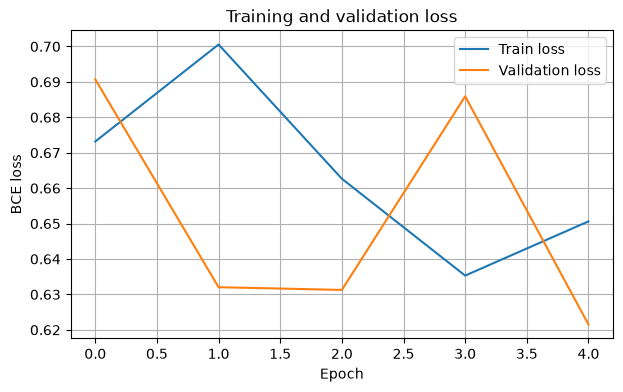

In [8]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss, total_items = 0.0, 0
    all_labels, all_probs = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            probs = torch.sigmoid(logits)
            total_loss += loss.item() * len(y)
            total_items += len(y)
            all_labels.extend(y.detach().cpu().numpy().astype(int).tolist())
            all_probs.extend(probs.detach().cpu().numpy().tolist())
    return total_loss / max(total_items, 1), np.array(all_labels), np.array(all_probs)

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_model_path = "best_fall_3dcnn.pt"

for epoch in range(EPOCHS):
    train_loss, _, _ = run_epoch(train_loader, training=True)
    val_loss, _, _ = run_epoch(val_loader, training=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | train loss={train_loss:.4f} | val loss={val_loss:.4f}")

model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
plt.figure(figsize=(7,4))
plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("BCE loss"); plt.title("Training and validation loss")
plt.legend(); plt.grid(True); plt.show()

## Test evaluation
Reports Accuracy, Precision, Recall, F1-score, AUROC, classification report, confusion matrix, and ROC curve. AUROC is undefined if the test set contains only one class; the code handles that case.

Test loss: 0.6375


,Accuracy,Precision,Recall,F1-score,AUROC
0,0.4545,0.0,0.0,0.0,0.7


              precision    recall  f1-score   support

Normal / ADL       0.50      0.83      0.62         6
        Fall       0.00      0.00      0.00         5

    accuracy                           0.45        11
   macro avg       0.25      0.42      0.31        11
weighted avg       0.27      0.45      0.34        11



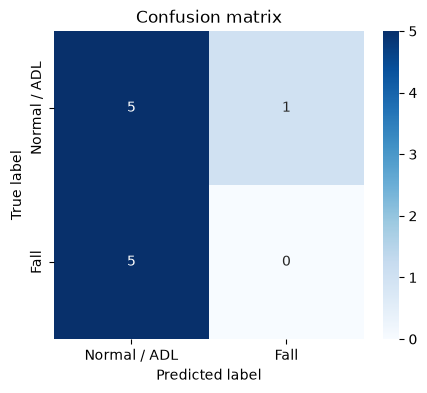

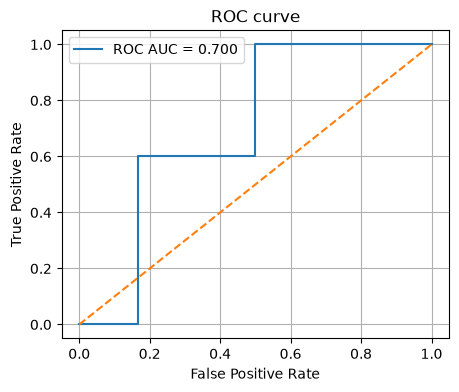

In [9]:
model.eval()
test_loss, y_true, y_prob = run_epoch(test_loader, training=False)
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1-score": f1_score(y_true, y_pred, zero_division=0),
    "AUROC": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
}
print("Test loss:", round(test_loss, 4))
display(pd.DataFrame([metrics]).round(4))
print(classification_report(y_true, y_pred, labels=[0,1],
                            target_names=["Normal / ADL", "Fall"], zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal / ADL", "Fall"],
            yticklabels=["Normal / ADL", "Fall"])
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title("Confusion matrix"); plt.show()

if len(np.unique(y_true)) == 2:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
    plt.plot([0,1], [0,1], linestyle="--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title("ROC curve"); plt.legend(); plt.grid(True); plt.show()
else:
    print("ROC curve/AUROC skipped because the test split contains only one class.")

## Review misclassifications
The table lists test clips where the thresholded prediction differs from the true label. Use the clip name and visual inspection to discuss camera view, occlusion, and motion blur.

In [10]:
results = test_df.reset_index(drop=True).copy()
results["true_label"] = y_true
results["fall_probability"] = y_prob
results["predicted_label"] = y_pred
results["true_name"] = results["true_label"].map({0:"Normal / ADL", 1:"Fall"})
results["predicted_name"] = results["predicted_label"].map({0:"Normal / ADL", 1:"Fall"})
errors = results[results["true_label"] != results["predicted_label"]]
print(f"Misclassified clips: {len(errors)} / {len(results)}")
display(errors[["filename", "true_name", "predicted_name", "fall_probability"]])

Misclassified clips: 6 / 11


,filename,true_name,predicted_name,fall_probability
1,adl-29-cam0-rgb,Normal / ADL,Fall,0.517486
3,fall-28-cam0-rgb,Fall,Normal / ADL,0.493025
5,fall-07-cam0-rgb,Fall,Normal / ADL,0.468935
6,fall-04-cam0-rgb,Fall,Normal / ADL,0.474451
9,fall-14-cam0-rgb,Fall,Normal / ADL,0.496876
10,fall-18-cam0-rgb,Fall,Normal / ADL,0.493811
